In [23]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import uncertainties as unc
import uncertainties.unumpy as unp
from scipy.optimize import curve_fit

In [24]:
# Constants
M_0 = 4 * np.pi * 10**-7
l = .285 # m
h0 = .108 # m
h0 = .250 - h0 # m
L = 1.826 # m
L_B = .215 # m

# Read dataset
data = pd.read_csv('./Current Balance Data.csv')

# Extracting the columns
mass = data['Mass (mg)'].to_numpy()
current = data['Current (AAC)'].to_numpy()
reading = data['Reading on the ruler (mm)'].to_numpy()

# Uncertainties
mass = unp.uarray(mass, 2/100 * mass) / 1e6 # ±2% uncertainty & convert to kg
reading = h0 - unp.uarray(reading, 1) / 1000 # ±1 mm & convert to meters
current_range = 20
current = unp.uarray(current, .5/100 * current + .3/100 * current_range) # ±(0.5% reading + 0.3% of range)

0.0 kg:
a = (1.55±0.24)×10⁻⁵
b = (8.39±2.51)×10⁻⁵
c = (3.94±0.05)×10⁻³
χ^2 = 1.6703925980339638
χ^2/ν = 0.5567975326779879

4e-07 kg:
a = (2.18±0.24)×10⁻⁵
b = (2.76±2.51)×10⁻⁵
c = (3.28±0.05)×10⁻³
χ^2 = 1.2724797670941501
χ^2/ν = 0.4241599223647167

8e-07 kg:
a = (2.16±0.24)×10⁻⁵
b = (4.50±2.51)×10⁻⁵
c = (2.35±0.05)×10⁻³
χ^2 = 1.8901947203817526
χ^2/ν = 0.6300649067939176

1.2e-06 kg:
a = (2.31±0.24)×10⁻⁵
b = (3.20±2.51)×10⁻⁵
c = (1.57±0.05)×10⁻³
χ^2 = 1.0906271671643608
χ^2/ν = 0.3635423890547869

1.6e-06 kg:
a = (1.76±0.24)×10⁻⁵
b = (9.06±2.51)×10⁻⁵
c = (7.76±0.53)×10⁻⁴
χ^2 = 3.839943528003347
χ^2/ν = 1.2799811760011157

2e-06 kg:
a = (1.89±0.24)×10⁻⁵
b = (9.76±2.51)×10⁻⁵
c = (-3.37±5.34)×10⁻⁵
χ^2 = 2.6296845590055513
χ^2/ν = 0.8765615196685171



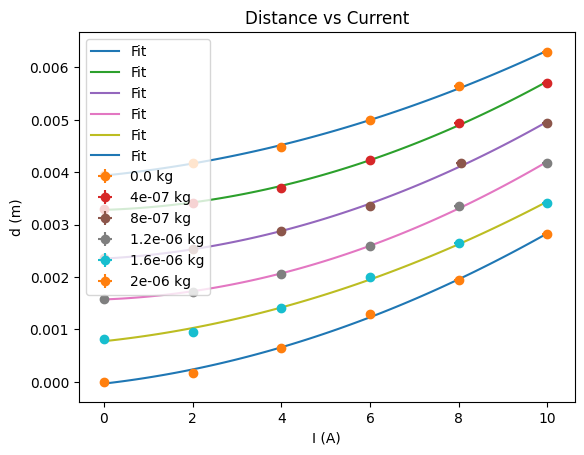

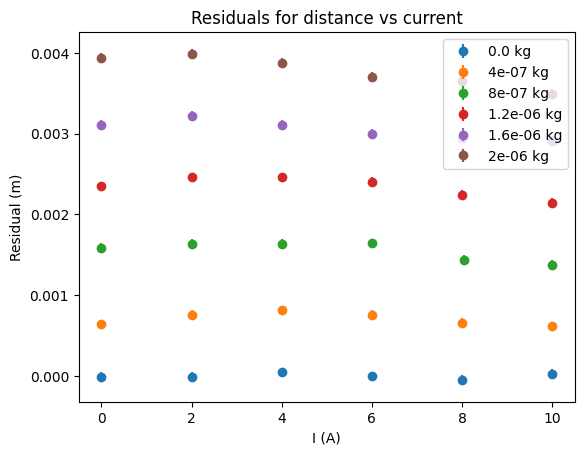

In [25]:
# Calculate the distance between the wires
# Take the reading from the max weight and 0 current as the rest position
# and calculate the distance between the wires relative to that

r0 = h0 - 161 / 1000 # m
theta0 = 1/2 * np.arctan(r0 / L) # rad

# Calculate the separation for each reading
thetas = 1/2 * unp.arctan(reading / L) - theta0
d = 2 * L_B * unp.sin(thetas / 2)

data = pd.DataFrame({'Mass': unp.std_devs(mass), 'Current': current, 'Distance': d, 'Angles': thetas})

# Group by mass
grouped = data.groupby('Mass')

# Fit the data
def fit(I, a, b, c):
    return a * I**2 + b * I + c

fit_params = []

# Plot the fit
fig, ax = plt.subplots()
for name, group in grouped:
    I = group['Current']
    d = group['Distance']
    popt, pcov = curve_fit(fit, unp.nominal_values(I), unp.nominal_values(d), sigma=unp.std_devs(d), absolute_sigma=True)
    a, b, c = unc.correlated_values(popt, pcov)
    x = np.linspace(0, 10, 100)
    ax.plot(x, fit(x, *popt), label='Fit')
    print(f'{name} kg:')
    print(f'a = {a:.2EP}')
    print(f'b = {b:.2EP}')
    print(f'c = {c:.2EP}')
    print(f'χ^2 = {np.sum((fit(unp.nominal_values(I), *popt) - unp.nominal_values(d))**2 / unp.std_devs(d)**2)}')
    print(f'χ^2/ν = {np.sum((fit(unp.nominal_values(I), *popt) - unp.nominal_values(d))**2 / unp.std_devs(d)**2) / (len(I) - 3)}\n')
    fit_params.append((a, b, c))
    ax.errorbar(unp.nominal_values(I), unp.nominal_values(d), xerr=unp.std_devs(I), yerr=unp.std_devs(d), fmt='o', label=f'{name} kg')
ax.set_title('Distance vs Current')
ax.set_xlabel('I (A)')
ax.set_ylabel('d (m)')
ax.legend()
plt.show()

# Plot the residuals
fig, ax = plt.subplots()
for name, group in grouped:
    I = group['Current']
    d = group['Distance']
    a, b, c = fit_params[int(name * 1000)]
    a = unc.nominal_value(a)
    b = unc.nominal_value(b)
    c = unc.nominal_value(c)
    ax.errorbar(unp.nominal_values(I), fit(unp.nominal_values(I), a, b, c) - unp.nominal_values(d), yerr=unp.std_devs(d), fmt='o', label=f'{name} kg')
ax.set_title('Residuals for distance vs current')
ax.set_xlabel('I (A)')
ax.set_ylabel('Residual (m)')
ax.legend()
plt.show()

Currents when the distance is 0.005m
Current required for deflection of 0.005m for 0.0 kg: 6.01 A
Current required for deflection of 0.005m for 4e-07 kg: 8.27 A
Current required for deflection of 0.005m for 8e-07 kg: 10.07 A
Current required for deflection of 0.005m for 1.2e-06 kg: 11.50 A
Current required for deflection of 0.005m for 1.6e-06 kg: 13.13 A
Current required for deflection of 0.005m for 2e-06 kg: 13.93 A



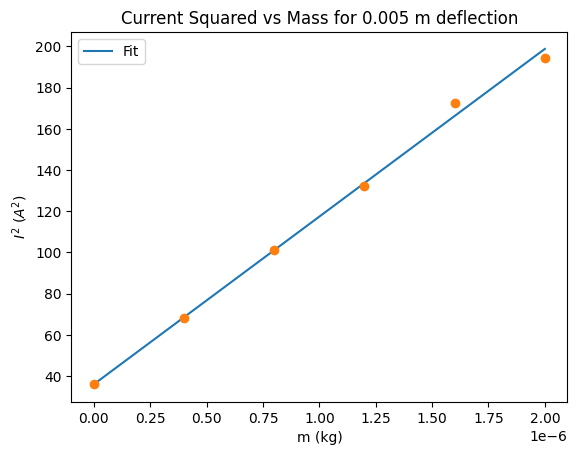

Fit for I^2 = a * m + b:
a = (8.13±0.06)×10⁷
b = (3.61±0.03)×10¹
χ^2 = 19.679464173810306
χ^2/ν = 4.9198660434525765
Mu_0 = (1.23+/-0.01)E-08 T m/A


In [ ]:
I_const_deflection = []

# Solve for the currents when the distance is 0.005m
print('Currents when the distance is 0.005m')
masses = np.array([name for name, group in grouped])
for i, (a, b, c) in enumerate(fit_params):
    a = unc.nominal_value(a)
    b = unc.nominal_value(b)
    c = unc.nominal_value(c)
    I = max(np.roots([a, b, c - 0.005]))
    I_const_deflection.append(I)
    print(f'Current required for deflection of 0.005m for {masses[i]} kg: {I:.2f} A')
I_const_deflection = np.array(I_const_deflection)
print()

# Fit the data
def fit2(m, a, b):
    return a * m + b

popt, pcov = curve_fit(fit2, masses, I_const_deflection**2, sigma=1 / 100 * I_const_deflection**2, absolute_sigma=True) # ±1% uncertainty
a, b = unc.correlated_values(popt, pcov)
x = np.linspace(0, 2e-6, 100)
plt.plot(x, fit2(x, *popt), label='Fit')
plt.errorbar(masses, I_const_deflection**2, yerr=1 / 100 * I_const_deflection**2, fmt='o')
plt.title('Current Squared vs Mass for 0.005 m deflection')
plt.xlabel('m (kg)')
plt.ylabel('$I^2$ $(A^2)$')
plt.legend()
plt.show()

print('Fit for I^2 = a * m + b:')
print(f'a = {a:.2EP}')
print(f'b = {b:.2EP}')
print(f'χ^2 = {np.sum((fit2(masses, *popt) - I_const_deflection**2)**2 / (1 / 100 * I_const_deflection**2)**2)}')
print(f'χ^2/ν = {np.sum((fit2(masses, *popt) - I_const_deflection**2)**2 / (1 / 100 * I_const_deflection**2)**2) / (len(masses) - 2)}')

# Calculate Mu_0
mu_0 = 1/a
print(f'Mu_0 = {mu_0:.2E} T m/A')